# Assignment 2 – Part A: β-VAE and VQ-VAE (+ PixelCNN prior) on CIFAR-10
**Course:** Unsupervised Deep Learning (S1-26_AIMLZG533)

*Submitted by* **Group 93**

| # | Name | BITS ID | Contribution |
|---|---|---|---|
| 1 | **Prajwal Shetty K P** | 2025AE05434 | Part B: WGAN (weight clipping) & WGAN-GP, training, random samples, FID |
| 2 | **Tanushi Agarwal** | 2025AE05410 | Part A: β-VAE (β ∈ {1,2,4,10}), VQ-VAE (K ∈ {512,256,128}) and the PixelCNN prior |
| 3 | **Shahabuddin** | 2025AE05328 | Data pipeline ([0,1] normalisation), PSNR/FID evaluation code, runs on the BITS lab GPU |
| 4 | **SANTHOSH M** | 2025AE05426 | Part C: comparative analysis (reconstruction error, sampling quality, speed) and the PDF report |
| 5 | **TUFAIL AHMAD** | 2025AE05400 | Visualisation (100-sample grids, training curves), result tables, HTML export & final review |

**Contents**
1. Setup, data, metrics (PSNR, FID)
2. β-VAE with β ∈ {1, 2, 4, 10}: training, PSNR vs epoch, FID
3. VQ-VAE with K ∈ {512, 256, 128}: reconstruction, latent maps, codebook quality
4. Gated PixelCNN prior on the discrete latents: sampling and generation, FID
5. Summary of Part A (the results are also saved to `outputs/results/partA_results.json`, which the Part C report uses)

## 1. Setup

In [1]:
# If anything is missing on the lab machine:
# %pip install -q torch torchvision torchmetrics torch-fidelity pandas matplotlib

import os, time, json, math, random, socket, platform, subprocess
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt
from torchmetrics.image.fid import FrechetInceptionDistance

# QUICK=1 -> tiny smoke test (few images / iterations). Must be 0 for the real run.
QUICK = os.environ.get("UDL_QUICK", "0") == "1"

SEED = 42
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

# NVIDIA (lab) -> Intel Arc (XPU) -> CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.backends.cudnn.benchmark = True
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

def sync():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "xpu": torch.xpu.synchronize()

OUT = "outputs_quick" if QUICK else "outputs"
FIG, RES, CKPT = [os.path.join(OUT, d) for d in ("figures", "results", "checkpoints")]
for d in (FIG, RES, CKPT):
    os.makedirs(d, exist_ok=True)

GPU_NAME = (torch.cuda.get_device_name(0) if device.type == "cuda" else
            torch.xpu.get_device_name(0) if device.type == "xpu" else "CPU " + platform.processor())
print("torch", torch.__version__, "| device:", device, "| QUICK mode:", QUICK)
print("Hardware:", GPU_NAME, "| host:", socket.gethostname())

torch 2.15.0+cu132 | device: cuda | QUICK mode: False
Hardware: NVIDIA GeForce RTX 4090 | host: 58941c599a50


### Hardware / lab infrastructure
The code was set up and tested on the BITS Prayogshala lab machine (screenshot: `Prayogshala_lab_screenshot.jpg`, submitted with this notebook). The final training run whose outputs appear in this notebook was executed on the hardware printed by the cell above and below (as permitted for this course). The next cell prints the host name and, on NVIDIA machines, the `nvidia-smi` output.

In [2]:
print("Host:", socket.gethostname(), "|", platform.platform())
try:
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("nvidia-smi not available on this machine (device in use: %s)" % device)

Host: 58941c599a50 | Linux-6.8.0-138-generic-x86_64-with-glibc2.39
Fri Nov  6 17:13:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.91.07              Driver Version: 595.91.07      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4090        On  |   00000000:01:00.0 Off |                  Off |
|  0%   39C    P8             19W /  450W |       4MiB /  24564MiB |      0%      Default |
|                                         |                        |     

## Dataset and preprocessing
CIFAR-10: 50,000 training and 10,000 test images, 32x32 RGB. As the assignment asks, the only preprocessing is scaling the pixels to **[0, 1]** (divide the uint8 values by 255).
The full dataset is only about 600 MB as float32, so we keep it on the GPU and take mini-batches with `randperm`. This was noticeably faster than a `DataLoader` for such small images.

train: (50000, 3, 32, 32) test: (10000, 3, 32, 32) | pixel range: [0.0, 1.0]


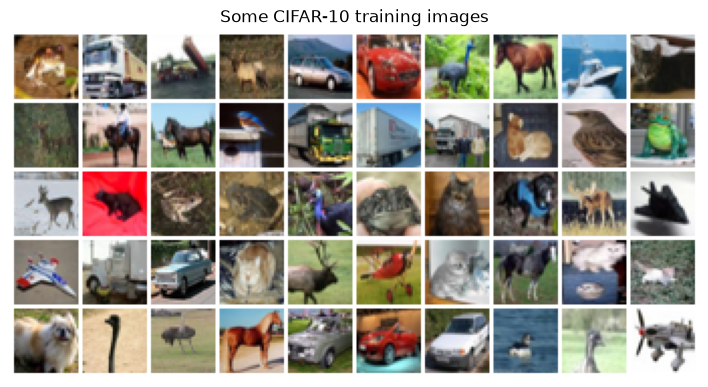

In [3]:
DATA_DIR = "./data"
train_set = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
test_set  = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)
CLASSES = train_set.classes

def to_tensor01(ds):
    # uint8 HWC -> float CHW in [0,1]
    return torch.from_numpy(ds.data).permute(0, 3, 1, 2).float().div(255.0)

X_train, X_test = to_tensor01(train_set), to_tensor01(test_set)
if QUICK:
    X_train, X_test = X_train[:1024], X_test[:512]
X_train, X_test = X_train.to(device), X_test.to(device)
print("train:", tuple(X_train.shape), "test:", tuple(X_test.shape),
      "| pixel range: [%.1f, %.1f]" % (X_train.min().item(), X_train.max().item()))

def batches(X, bs, shuffle=True):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        yield X[idx[i:i + bs]]

def show_grid(x, nrow=10, title=None, path=None, figsize=None):
    grid = make_grid(x.detach().float().cpu().clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0)
    if path is not None:
        save_image(grid, path)
    plt.figure(figsize=figsize or (nrow * 0.9, math.ceil(len(x) / nrow) * 0.9))
    plt.imshow(grid.permute(1, 2, 0).numpy()); plt.axis("off")
    if title: plt.title(title)
    plt.show()

def n_params(m):
    return sum(p.numel() for p in m.parameters())

show_grid(X_train[:50], nrow=10, title="Some CIFAR-10 training images")

## Evaluation metrics
* **PSNR** (dB) $= 10\log_{10}(1/\text{MSE})$ for each test image, then averaged. Pixels are in [0,1], so MAX = 1.
* **FID**: we use `torchmetrics`' `FrechetInceptionDistance` (2048-d pool3 Inception-v3 features). The reference set is always the **10,000 CIFAR-10 test images**, and each model is scored on **10,000 generated images**, so all the FID numbers in Part A and Part B can be compared directly. We compute the real-image statistics once and reuse them for every model.

In [4]:
@torch.no_grad()
def psnr_per_image(x_hat, x):
    mse = F.mse_loss(x_hat.clamp(0, 1), x, reduction="none").flatten(1).mean(1)
    return 10 * torch.log10(1.0 / mse.clamp_min(1e-10))

class FIDScorer:
    """FID with torchmetrics' Inception-v3 (2048-d pool features).
    The features are extracted on the GPU in float32; the mean/covariance statistics are accumulated in
    float64 on the CPU. This gives the same result as torchmetrics' FrechetInceptionDistance and also works on
    GPUs without float64 support (e.g. Intel Arc). Real statistics (CIFAR-10 test set) are computed once."""
    def __init__(self, real, bs=500):
        self.inception = FrechetInceptionDistance(feature=2048, normalize=True).inception.to(device).eval()
        self.mu_r, self.sigma_r = self._stats(real[i:i + bs] for i in range(0, len(real), bs))

    @torch.no_grad()
    def _stats(self, batch_iter):
        s, ss, n = torch.zeros(2048, dtype=torch.float64), torch.zeros(2048, 2048, dtype=torch.float64), 0
        for x in batch_iter:
            f = self.inception((x.clamp(0, 1).to(device) * 255).byte()).double().cpu()
            s += f.sum(0); ss += f.t() @ f; n += len(f)
        mu = s / n
        return mu, (ss - n * torch.outer(mu, mu)) / (n - 1)

    def __call__(self, batch_iter):
        mu, sigma = self._stats(batch_iter)
        tr_covmean = torch.linalg.eigvals(sigma @ self.sigma_r).sqrt().real.sum()
        return float((mu - self.mu_r).square().sum() + sigma.trace() + self.sigma_r.trace() - 2 * tr_covmean)

def sample_batches(sample_fn, n, bs=500):
    done = 0
    while done < n:
        b = min(bs, n - done)
        yield sample_fn(b)
        done += b

def timed(fn):
    sync(); t = time.time(); out = fn(); sync()
    return out, time.time() - t

t = time.time()
fid_scorer = FIDScorer(X_test)
print(f"Real Inception statistics ready ({len(X_test)} test images, {time.time() - t:.1f}s)")

Real Inception statistics ready (10000 test images, 9.3s)


In [5]:
CFG = dict(
    bs=128,
    # beta-VAE
    betas=[1, 2, 4, 10], z_dim=128, vae_epochs=50, vae_lr=1e-3,
    # VQ-VAE
    Ks=[512, 256, 128], emb_dim=64, vq_hidden=256, vq_res_hidden=64, vq_epochs=40, vq_lr=5e-4, commit_beta=0.25,
    # PixelCNN prior
    pcnn_dim=128, pcnn_layers=12, pcnn_epochs=40, pcnn_lr=3e-4,
    n_fid=10000,
)
if QUICK:
    CFG.update(betas=[1, 10], Ks=[256], vae_epochs=2, vq_epochs=2, pcnn_epochs=2, n_fid=256)
results = {"config": CFG, "device": str(device), "gpu_name": f"{GPU_NAME} (host {socket.gethostname()})", "vae": {}, "vqvae": {}}
CFG

{'bs': 128,
 'betas': [1, 2, 4, 10],
 'z_dim': 128,
 'vae_epochs': 50,
 'vae_lr': 0.001,
 'Ks': [512, 256, 128],
 'emb_dim': 64,
 'vq_hidden': 256,
 'vq_res_hidden': 64,
 'vq_epochs': 40,
 'vq_lr': 0.0005,
 'commit_beta': 0.25,
 'pcnn_dim': 128,
 'pcnn_layers': 12,
 'pcnn_epochs': 40,
 'pcnn_lr': 0.0003,
 'n_fid': 10000}

## 2. β-VAE

**Model.** A convolutional VAE: three stride-2 conv layers (32→16→8→4) map the image to a 128-d Gaussian posterior $q(z|x)=\mathcal N(\mu,\sigma^2)$, and the decoder mirrors this with transposed convs and a sigmoid output.

**Objective.** The pixels are in [0,1], so we use a Bernoulli (BCE) likelihood, summed over pixels:
$$\mathcal L_\beta = \mathbb E_{q(z|x)}[-\log p(x|z)] + \beta\, D_{KL}\big(q(z|x)\,\|\,\mathcal N(0,I)\big)$$
β = 1 is the standard VAE. A larger β puts more weight on the KL term, which pushes the posterior towards the prior. This tends to give more disentangled but blurrier reconstructions and fewer active latent dimensions.

For **PSNR** we reconstruct from the posterior mean $\mu$. For **FID** we draw $z\sim\mathcal N(0,I)$ and decode it (sample FID). We also report the FID of the test-set reconstructions as a second reference point.

In [6]:
class ConvVAE(nn.Module):
    def __init__(self, z_dim=128):
        super().__init__()
        self.z_dim = z_dim
        self.enc = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1),    nn.BatchNorm2d(64),  nn.LeakyReLU(0.2, True),   # 16x16
            nn.Conv2d(64, 128, 4, 2, 1),  nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),   # 8x8
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),   # 4x4
            nn.Flatten())
        self.fc_mu = nn.Linear(256 * 16, z_dim)
        self.fc_logvar = nn.Linear(256 * 16, z_dim)
        self.fc_dec = nn.Linear(z_dim, 256 * 16)
        self.dec = nn.Sequential(
            nn.Unflatten(1, (256, 4, 4)), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),     # 8x8
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  nn.BatchNorm2d(64),  nn.ReLU(True),     # 16x16
            nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Sigmoid())                              # 32x32

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z):
        return self.dec(self.fc_dec(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)   # reparameterisation trick
        return self.decode(z), mu, logvar

    @torch.no_grad()
    def sample(self, n):
        return self.decode(torch.randn(n, self.z_dim, device=device))


def vae_loss(x_hat, x, mu, logvar, beta):
    rec = F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)
    kl = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(1)).mean()
    return rec + beta * kl, rec, kl


@torch.no_grad()
def eval_vae(model):
    model.eval()
    psnrs, kls = [], []
    for x in batches(X_test, 500, shuffle=False):
        mu, logvar = model.encode(x)
        psnrs.append(psnr_per_image(model.decode(mu), x))
        kls.append(-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()))      # per-dimension KL
    kl_dim = torch.cat(kls).mean(0)
    return torch.cat(psnrs).mean().item(), kl_dim.sum().item(), int((kl_dim > 0.01).sum())

print("VAE parameters: %.2fM" % (n_params(ConvVAE(CFG["z_dim"])) / 1e6))

VAE parameters: 2.90M


In [7]:
def train_vae(beta):
    path = f"{CKPT}/vae_beta{beta}.pt"
    model = ConvVAE(CFG["z_dim"]).to(device)
    if os.path.exists(path):                        # resume support (lab sessions sometimes time out)
        ck = torch.load(path, map_location=device)
        model.load_state_dict(ck["model"]); print(f"beta={beta}: loaded checkpoint")
        return model, ck["hist"]
    opt = torch.optim.Adam(model.parameters(), lr=CFG["vae_lr"])
    hist = {k: [] for k in ["epoch", "loss", "rec", "kl", "test_psnr", "test_kl", "active_dims", "time"]}
    t0 = time.time()
    for ep in range(1, CFG["vae_epochs"] + 1):
        model.train()
        s, n = torch.zeros(3, device=device), 0
        for x in batches(X_train, CFG["bs"]):
            x_hat, mu, logvar = model(x)
            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            s += torch.stack([loss, rec, kl]).detach() * len(x); n += len(x)
        s = (s / n).tolist()
        psnr, test_kl, active = eval_vae(model)
        for k, v in zip(hist, [ep, *s, psnr, test_kl, active, time.time() - t0]):
            hist[k].append(v)
        if ep == 1 or ep % 5 == 0 or ep == CFG["vae_epochs"]:
            print(f"beta={beta:>2} ep {ep:3d} | loss {s[0]:8.2f} rec {s[1]:8.2f} KL {s[2]:6.2f} "
                  f"| test PSNR {psnr:5.2f} dB | active dims {active:3d} | {time.time() - t0:6.0f}s")
    torch.save({"model": model.state_dict(), "hist": hist}, path)
    return model, hist

vaes, vae_hist = {}, {}
for beta in CFG["betas"]:
    seed_everything(SEED)
    vaes[beta], vae_hist[beta] = train_vae(beta)

beta= 1 ep   1 | loss  1912.01 rec  1877.36 KL  34.65 | test PSNR 17.89 dB | active dims 128 |      1s


beta= 1 ep   5 | loss  1828.53 rec  1786.06 KL  42.48 | test PSNR 19.81 dB | active dims 117 |      4s


beta= 1 ep  10 | loss  1822.47 rec  1778.40 KL  44.08 | test PSNR 20.24 dB | active dims 105 |      8s


beta= 1 ep  15 | loss  1820.18 rec  1775.57 KL  44.62 | test PSNR 20.41 dB | active dims 104 |     12s


beta= 1 ep  20 | loss  1818.21 rec  1773.20 KL  45.01 | test PSNR 20.39 dB | active dims 104 |     16s


beta= 1 ep  25 | loss  1817.12 rec  1771.88 KL  45.24 | test PSNR 20.39 dB | active dims 101 |     20s


... (34 outputs left out)

beta=10 ep  35 | loss  1953.11 rec  1887.27 KL   6.58 | test PSNR 16.74 dB | active dims  11 |     26s


beta=10 ep  40 | loss  1952.78 rec  1886.94 KL   6.58 | test PSNR 16.85 dB | active dims  11 |     30s


beta=10 ep  45 | loss  1952.39 rec  1886.44 KL   6.60 | test PSNR 16.85 dB | active dims  10 |     34s


beta=10 ep  50 | loss  1951.82 rec  1886.09 KL   6.57 | test PSNR 16.75 dB | active dims  11 |     38s


### 2.1 Reconstruction quality (PSNR) vs epochs

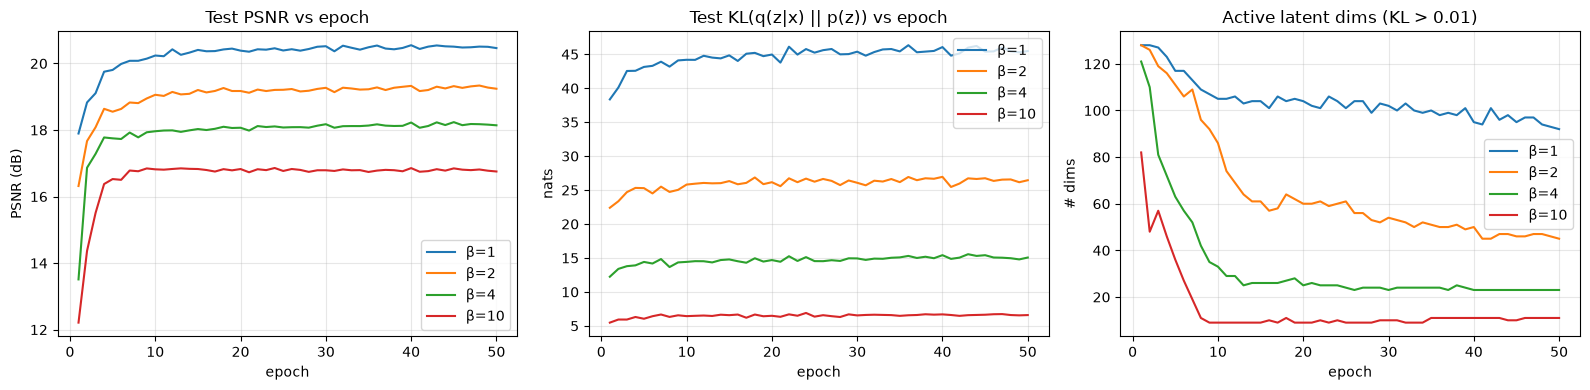

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for beta in CFG["betas"]:
    h = vae_hist[beta]
    ax[0].plot(h["epoch"], h["test_psnr"], label=f"β={beta}")
    ax[1].plot(h["epoch"], h["test_kl"], label=f"β={beta}")
    ax[2].plot(h["epoch"], h["active_dims"], label=f"β={beta}")
ax[0].set(title="Test PSNR vs epoch", xlabel="epoch", ylabel="PSNR (dB)")
ax[1].set(title="Test KL(q(z|x) || p(z)) vs epoch", xlabel="epoch", ylabel="nats")
ax[2].set(title="Active latent dims (KL > 0.01)", xlabel="epoch", ylabel="# dims")
for a in ax: a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/vae_psnr_vs_epoch.png", dpi=150); plt.show()

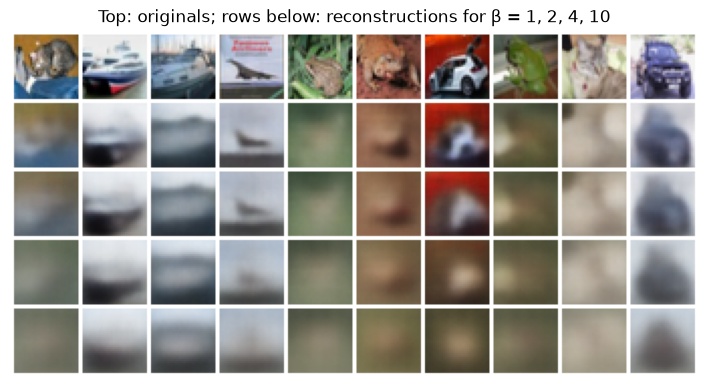

In [9]:
# originals (top row) and reconstructions for each beta
x = X_test[:10]
rows = [x]
with torch.no_grad():
    for beta in CFG["betas"]:
        vaes[beta].eval(); rows.append(vaes[beta].decode(vaes[beta].encode(x)[0]))
show_grid(torch.cat(rows), nrow=10, path=f"{FIG}/vae_reconstructions.png",
          title="Top: originals; rows below: reconstructions for β = " + ", ".join(map(str, CFG["betas"])))

### 2.2 Samples from the prior and FID for each β

beta= 1: PSNR 20.46 dB | sample FID 144.70 | recon FID 145.29


beta= 2: PSNR 19.24 dB | sample FID 175.95 | recon FID 182.90


beta= 4: PSNR 18.14 dB | sample FID 224.03 | recon FID 235.99


beta=10: PSNR 16.75 dB | sample FID 297.41 | recon FID 300.23


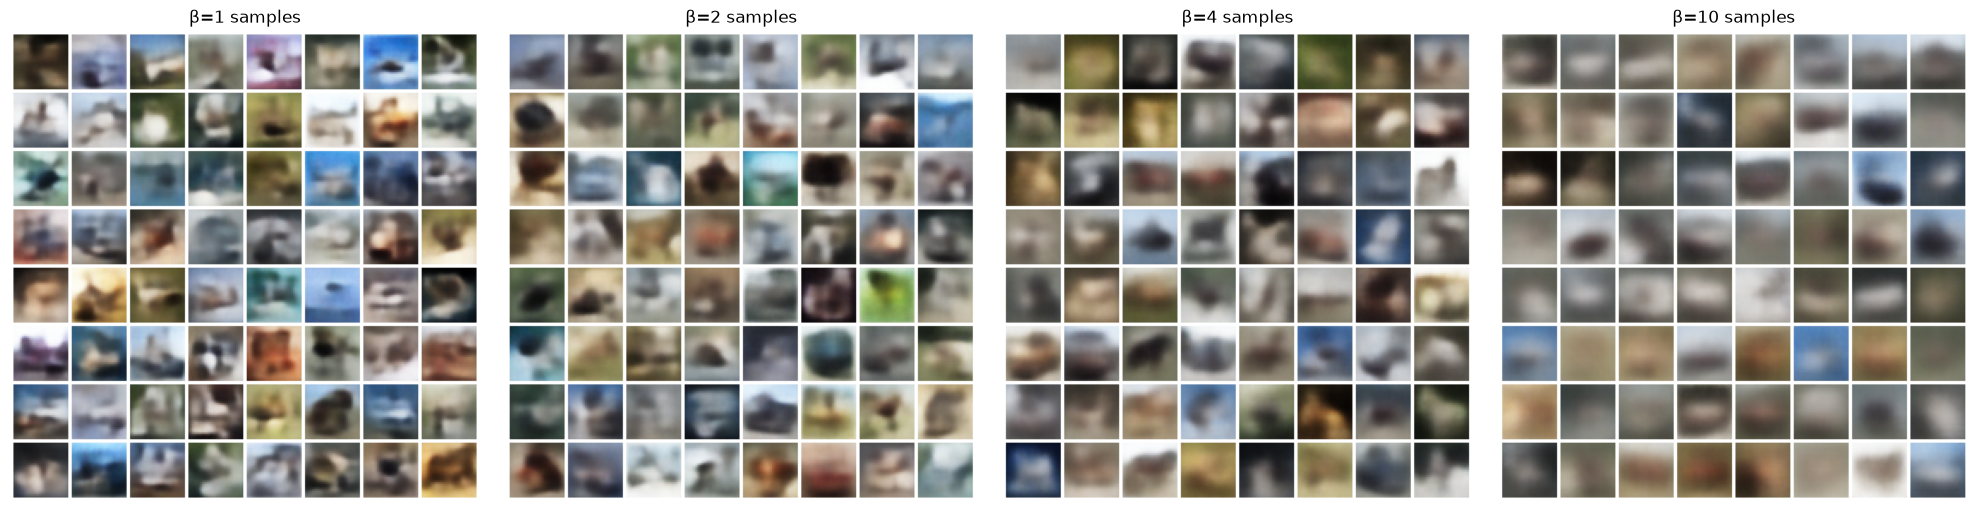

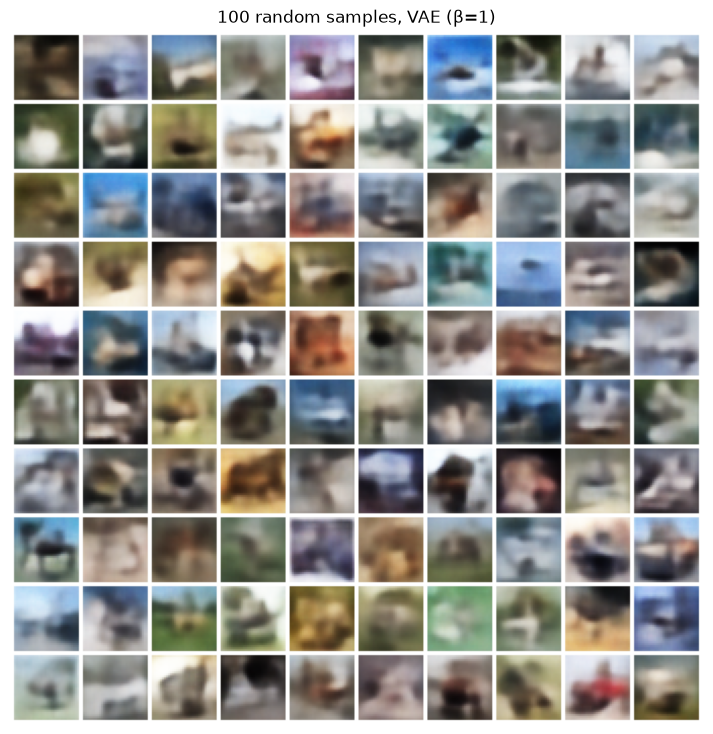

In [10]:
for beta in CFG["betas"]:
    model = vaes[beta].eval()
    seed_everything(SEED)
    _, t_sample = timed(lambda: [model.sample(500) for _ in range(CFG["n_fid"] // 500 or 1)])
    seed_everything(SEED)
    fid_sample = fid_scorer(sample_batches(model.sample, CFG["n_fid"]))
    fid_recon = fid_scorer(model.decode(model.encode(xb)[0]) for xb in batches(X_test, 500, shuffle=False))
    h = vae_hist[beta]
    results["vae"][str(beta)] = dict(
        psnr_hist=h["test_psnr"], kl_hist=h["test_kl"], final_psnr=h["test_psnr"][-1],
        final_kl=h["test_kl"][-1], active_dims=h["active_dims"][-1],
        fid_sample=fid_sample, fid_recon=fid_recon,
        train_time_s=h["time"][-1], sample_time_10k_s=t_sample * 10000 / max(CFG["n_fid"], 500),
        params=n_params(model))
    print(f"beta={beta:>2}: PSNR {h['test_psnr'][-1]:.2f} dB | sample FID {fid_sample:.2f} | recon FID {fid_recon:.2f}")

seed_everything(SEED)
fig, ax = plt.subplots(1, len(CFG["betas"]), figsize=(5 * len(CFG["betas"]), 5))
for a, beta in zip(np.atleast_1d(ax), CFG["betas"]):
    g = make_grid(vaes[beta].sample(64).cpu(), nrow=8, pad_value=1)
    a.imshow(g.permute(1, 2, 0)); a.axis("off"); a.set_title(f"β={beta} samples")
plt.tight_layout(); plt.savefig(f"{FIG}/vae_samples_all_betas.png", dpi=150); plt.show()

seed_everything(SEED)
show_grid(vaes[CFG["betas"][0]].sample(100), nrow=10, path=f"{FIG}/vae_beta1_samples_100.png",
          title="100 random samples, VAE (β=1)", figsize=(9, 9))

In [11]:
vae_df = pd.DataFrame({f"β={b}": {"Test PSNR (dB)": r["final_psnr"], "Test KL (nats)": r["final_kl"],
                                   "Active dims /128": r["active_dims"], "Sample FID ↓": r["fid_sample"],
                                   "Recon FID ↓": r["fid_recon"], "Train time (s)": r["train_time_s"]}
                       for b, r in ((int(k), v) for k, v in results["vae"].items())}).T
json.dump(results, open(f"{RES}/partA_results.json", "w"), indent=2)
vae_df.round(2)

,Test PSNR (dB),Test KL (nats),Active dims /128,Sample FID ↓,Recon FID ↓,Train time (s)
β=1,20.46,45.47,92.0,144.70,145.29,38.53
β=2,19.24,26.45,45.0,175.95,182.90,38.14
β=4,18.14,15.06,23.0,224.03,235.99,37.88
β=10,16.75,6.59,11.0,297.41,300.23,38.04


In [12]:
# quick sanity checks on the trends we expect from beta-VAE theory
b = sorted(int(k) for k in results["vae"])
ps = [results["vae"][str(k)]["final_psnr"] for k in b]
fs = [results["vae"][str(k)]["fid_sample"] for k in b]
print("PSNR decreases as beta increases :", all(ps[i] >= ps[i + 1] for i in range(len(ps) - 1)), np.round(ps, 2))
print("Best sample FID at beta =", b[int(np.argmin(fs))], "| FIDs:", np.round(fs, 1))

PSNR decreases as beta increases : True [20.46 19.24 18.14 16.75]
Best sample FID at beta = 1 | FIDs: [144.7 175.9 224.  297.4]


**Observations (β-VAE)**
* **PSNR vs epoch.** Every model improves quickly in the first ~10 epochs and then levels off. The curves are ordered by β: β=1 reconstructs best and β=10 worst. Raising β makes the KL term more expensive, so the encoder puts less information into $z$ (look at the falling test KL and the number of active latent dimensions), and the decoder can only produce an "average" blurry image.
* **FID.** All the VAEs have high FID because both the reconstructions and the samples are blurry. Inception features are very sensitive to missing high-frequency detail. There are two competing effects. A larger β reduces the gap between the aggregate posterior and the prior, so prior samples land in regions the decoder has actually seen. But it also removes detail. For large β the second effect wins, and the β=10 samples are mostly smooth colour blobs.
* The **recon FID** is always lower than the **sample FID**. This shows that part of the gap comes from the prior/posterior mismatch (the "holes" in latent space), and part from the Gaussian likelihood/decoder itself.

## 3. VQ-VAE

**Model** (van den Oord et al., 2017). The encoder downsamples 32×32 → **8×8** with two stride-2 convs, followed by two residual blocks, and outputs $z_e(x)\in\mathbb R^{8\times8\times64}$. Each 64-d vector is replaced by its nearest codebook entry $e_k$, $k\in\{1..K\}$. The decoder mirrors the encoder. Gradients pass through the quantiser with the straight-through estimator.

**Loss:** $\|x-\hat x\|^2 + \beta_c\,\|z_e - \mathrm{sg}[e]\|^2$ with $\beta_c = 0.25$. The codebook is updated with **exponential moving averages** (decay 0.99) rather than the codebook loss, which the paper also recommends. We add **dead-code restarts**: a code whose EMA usage drops below 0.1 is re-initialised to a random encoder output from the current batch. Without this, a large share of the K=512 codebook went unused in our first attempts.

**Codebook quality** is measured on the test set with:
* **Perplexity** $= \exp(-\sum_k p_k\log p_k)$, the effective number of codes in use (the maximum is K)
* **Usage**: the fraction of codes that are used at least once
* **Dead codes**: the number of codes that are never selected

In [13]:
class VectorQuantizerEMA(nn.Module):
    def __init__(self, K, D, beta=0.25, decay=0.99, eps=1e-5, restart_thresh=0.1):
        super().__init__()
        self.K, self.D, self.beta, self.decay, self.eps, self.restart_thresh = K, D, beta, decay, eps, restart_thresh
        embed = torch.randn(K, D) * 0.1
        self.register_buffer("embedding", embed)
        self.register_buffer("ema_count", torch.zeros(K))
        self.register_buffer("ema_w", embed.clone())

    def forward(self, z):                                    # z: B x D x H x W
        z = z.permute(0, 2, 3, 1).contiguous()
        flat = z.view(-1, self.D)
        dist = (flat.pow(2).sum(1, keepdim=True) - 2 * flat @ self.embedding.t()
                + self.embedding.pow(2).sum(1))
        idx = dist.argmin(1)
        onehot = F.one_hot(idx, self.K).type(flat.dtype)
        q = self.embedding[idx].view(z.shape)

        if self.training:                                     # EMA codebook update (no gradient)
            with torch.no_grad():
                self.ema_count.mul_(self.decay).add_(onehot.sum(0), alpha=1 - self.decay)
                n = self.ema_count.sum()
                count = (self.ema_count + self.eps) / (n + self.K * self.eps) * n   # Laplace smoothing
                self.ema_w.mul_(self.decay).add_(onehot.t() @ flat, alpha=1 - self.decay)
                self.embedding.copy_(self.ema_w / count.unsqueeze(1))
                # dead-code restart: unused codes jump to random encoder outputs of this batch
                dead = self.ema_count < self.restart_thresh
                rand = flat[torch.randint(0, flat.size(0), (self.K,), device=flat.device)]
                self.embedding.copy_(torch.where(dead[:, None], rand, self.embedding))
                self.ema_w.copy_(torch.where(dead[:, None], rand, self.ema_w))
                self.ema_count.copy_(torch.where(dead, torch.ones_like(self.ema_count), self.ema_count))

        commit = self.beta * F.mse_loss(z, q.detach())
        q = z + (q - z).detach()                              # straight-through estimator
        p = onehot.mean(0)
        perplexity = torch.exp(-(p * torch.log(p + 1e-10)).sum())
        return q.permute(0, 3, 1, 2).contiguous(), commit, perplexity, idx.view(z.shape[:-1])


class ResBlock(nn.Module):
    def __init__(self, ch, hid):
        super().__init__()
        self.block = nn.Sequential(nn.ReLU(), nn.Conv2d(ch, hid, 3, 1, 1), nn.ReLU(), nn.Conv2d(hid, ch, 1))
    def forward(self, x):
        return x + self.block(x)


class VQVAE(nn.Module):
    def __init__(self, K, D=64, ch=256, res_ch=64):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3, ch // 2, 4, 2, 1), nn.ReLU(True),           # 16x16
            nn.Conv2d(ch // 2, ch, 4, 2, 1), nn.ReLU(True),          # 8x8
            nn.Conv2d(ch, ch, 3, 1, 1),
            ResBlock(ch, res_ch), ResBlock(ch, res_ch), nn.ReLU(True),
            nn.Conv2d(ch, D, 1))
        self.vq = VectorQuantizerEMA(K, D, beta=CFG["commit_beta"])
        self.dec = nn.Sequential(
            nn.Conv2d(D, ch, 3, 1, 1),
            ResBlock(ch, res_ch), ResBlock(ch, res_ch), nn.ReLU(True),
            nn.ConvTranspose2d(ch, ch // 2, 4, 2, 1), nn.ReLU(True), # 16x16
            nn.ConvTranspose2d(ch // 2, 3, 4, 2, 1), nn.Sigmoid())   # 32x32

    def forward(self, x):
        q, commit, perp, idx = self.vq(self.enc(x))
        return self.dec(q), commit, perp, idx

    @torch.no_grad()
    def encode_indices(self, x):
        return self.vq(self.enc(x))[3]

    @torch.no_grad()
    def decode_indices(self, idx):                               # idx: B x 8 x 8 (long)
        return self.dec(self.vq.embedding[idx].permute(0, 3, 1, 2).contiguous())

print("VQ-VAE parameters: %.2fM" % (n_params(VQVAE(256, CFG["emb_dim"], CFG["vq_hidden"], CFG["vq_res_hidden"])) / 1e6))

VQ-VAE parameters: 2.47M


In [14]:
@torch.no_grad()
def eval_vq(model):
    model.eval()
    psnrs, counts = [], torch.zeros(model.vq.K, device=device)
    for x in batches(X_test, 500, shuffle=False):
        x_hat, _, _, idx = model(x)
        psnrs.append(psnr_per_image(x_hat, x))
        counts += torch.bincount(idx.flatten(), minlength=model.vq.K).float()
    p = counts / counts.sum()
    perp = torch.exp(-(p * torch.log(p + 1e-10)).sum()).item()
    return torch.cat(psnrs).mean().item(), perp, (counts > 0).float().mean().item(), int((counts == 0).sum()), counts.cpu()


def train_vqvae(K):
    path = f"{CKPT}/vqvae_K{K}.pt"
    model = VQVAE(K, CFG["emb_dim"], CFG["vq_hidden"], CFG["vq_res_hidden"]).to(device)
    if os.path.exists(path):
        ck = torch.load(path, map_location=device)
        model.load_state_dict(ck["model"]); print(f"K={K}: loaded checkpoint")
        return model, ck["hist"]
    opt = torch.optim.Adam(model.parameters(), lr=CFG["vq_lr"])
    steps = CFG["vq_epochs"] * math.ceil(len(X_train) / CFG["bs"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    hist = {k: [] for k in ["epoch", "rec_mse", "test_psnr", "test_perplexity", "usage", "time"]}
    t0 = time.time()
    for ep in range(1, CFG["vq_epochs"] + 1):
        model.train()
        s, n = torch.zeros(1, device=device), 0
        for x in batches(X_train, CFG["bs"]):
            x_hat, commit, _, _ = model(x)
            rec = F.mse_loss(x_hat, x)
            loss = rec + commit
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); sched.step()
            s += rec.detach() * len(x); n += len(x)
        psnr, perp, usage, dead, _ = eval_vq(model)
        for k, v in zip(hist, [ep, (s / n).item(), psnr, perp, usage, time.time() - t0]):
            hist[k].append(v)
        if ep == 1 or ep % 5 == 0 or ep == CFG["vq_epochs"]:
            print(f"K={K:>3} ep {ep:3d} | train MSE {(s / n).item():.5f} | test PSNR {psnr:5.2f} dB | "
                  f"perplexity {perp:6.1f} | usage {usage * 100:5.1f}% | {time.time() - t0:6.0f}s")
    torch.save({"model": model.state_dict(), "hist": hist}, path)
    return model, hist

vqvaes, vq_hist = {}, {}
for K in CFG["Ks"]:
    seed_everything(SEED)
    vqvaes[K], vq_hist[K] = train_vqvae(K)

K=512 ep   1 | train MSE 0.01611 | test PSNR 21.69 dB | perplexity  376.1 | usage  95.3% |      2s


K=512 ep   5 | train MSE 0.00421 | test PSNR 24.44 dB | perplexity  476.0 | usage 100.0% |      7s


K=512 ep  10 | train MSE 0.00383 | test PSNR 24.83 dB | perplexity  459.5 | usage 100.0% |     14s


K=512 ep  15 | train MSE 0.00343 | test PSNR 25.21 dB | perplexity  449.1 | usage 100.0% |     21s


K=512 ep  20 | train MSE 0.00329 | test PSNR 25.35 dB | perplexity  437.1 | usage 100.0% |     28s


K=512 ep  25 | train MSE 0.00321 | test PSNR 25.44 dB | perplexity  440.6 | usage 100.0% |     34s


... (17 outputs left out)

K=128 ep  25 | train MSE 0.00405 | test PSNR 24.41 dB | perplexity  113.2 | usage 100.0% |     33s


K=128 ep  30 | train MSE 0.00399 | test PSNR 24.46 dB | perplexity  113.0 | usage 100.0% |     39s


K=128 ep  35 | train MSE 0.00396 | test PSNR 24.49 dB | perplexity  113.5 | usage 100.0% |     46s


K=128 ep  40 | train MSE 0.00395 | test PSNR 24.49 dB | perplexity  113.4 | usage 100.0% |     52s


### 3.1 Reconstruction quality and codebook quality

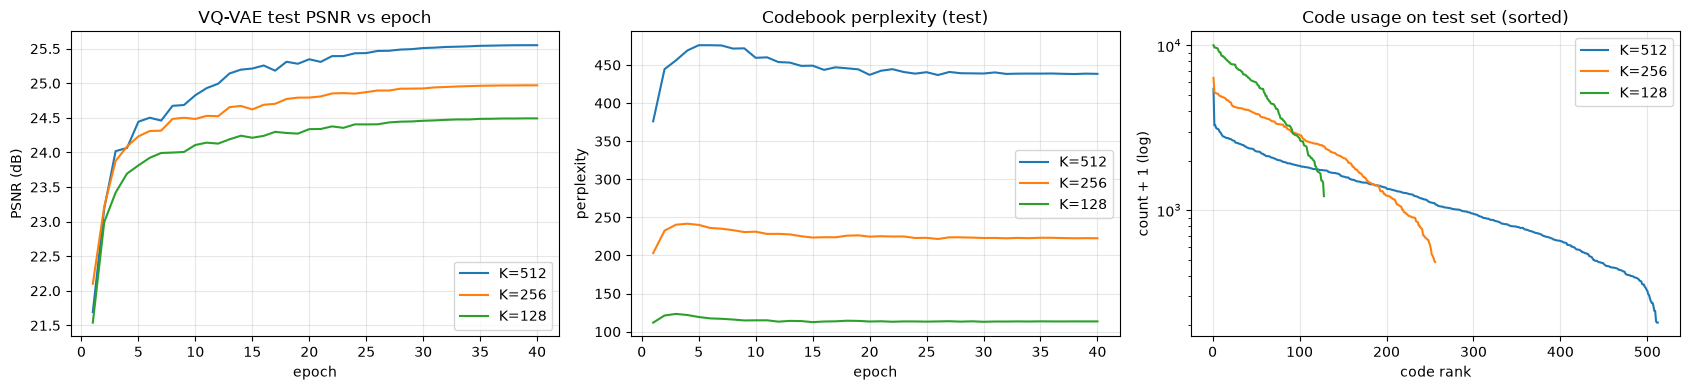

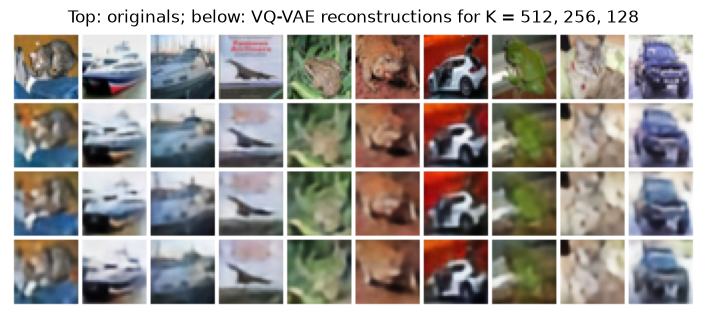

In [15]:
vq_eval = {K: eval_vq(vqvaes[K]) for K in CFG["Ks"]}

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for K in CFG["Ks"]:
    h = vq_hist[K]
    ax[0].plot(h["epoch"], h["test_psnr"], label=f"K={K}")
    ax[1].plot(h["epoch"], h["test_perplexity"], label=f"K={K}")
    c = np.sort(vq_eval[K][4].numpy())[::-1]
    ax[2].semilogy(np.arange(1, len(c) + 1), c + 1, label=f"K={K}")
ax[0].set(title="VQ-VAE test PSNR vs epoch", xlabel="epoch", ylabel="PSNR (dB)")
ax[1].set(title="Codebook perplexity (test)", xlabel="epoch", ylabel="perplexity")
ax[2].set(title="Code usage on test set (sorted)", xlabel="code rank", ylabel="count + 1 (log)")
for a in ax: a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/vqvae_psnr_codebook.png", dpi=150); plt.show()

x = X_test[:10]
rows = [x] + [vqvaes[K].eval()(x)[0] for K in CFG["Ks"]]
show_grid(torch.cat(rows), nrow=10, path=f"{FIG}/vqvae_reconstructions.png",
          title="Top: originals; below: VQ-VAE reconstructions for K = " + ", ".join(map(str, CFG["Ks"])))

### 3.2 Extracting the discrete latent maps
Every image now becomes an 8×8 grid of integer codes. The PixelCNN prior is trained on these grids, which come from the training set; the test-set grids are used to measure validation NLL. The figure shows a few test images next to their code maps (each colour is one code index). You can see that regions of similar colour/texture, such as the sky or background, reuse the same codes.

K=512: train latents (50000, 8, 8), test latents (10000, 8, 8), dtype torch.int64


K=256: train latents (50000, 8, 8), test latents (10000, 8, 8), dtype torch.int64


K=128: train latents (50000, 8, 8), test latents (10000, 8, 8), dtype torch.int64


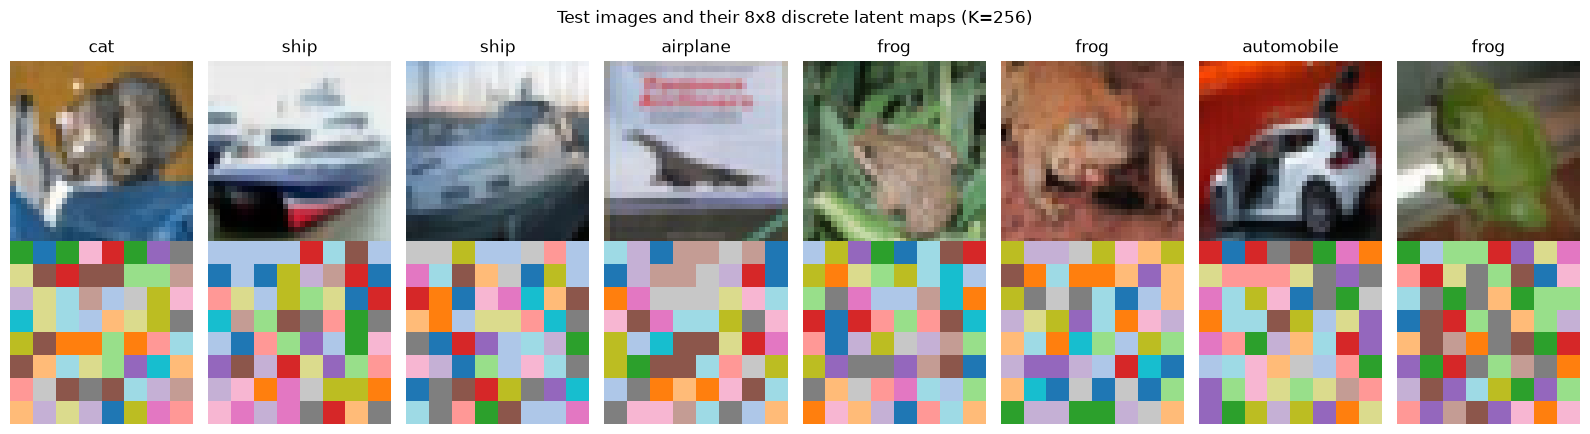

In [16]:
latents = {}
for K in CFG["Ks"]:
    m = vqvaes[K].eval()
    tr = torch.cat([m.encode_indices(xb) for xb in batches(X_train, 1000, shuffle=False)])
    te = torch.cat([m.encode_indices(xb) for xb in batches(X_test, 1000, shuffle=False)])
    latents[K] = (tr, te)
    torch.save({"train": tr.cpu(), "test": te.cpu()}, f"{CKPT}/latents_K{K}.pt")
    print(f"K={K}: train latents {tuple(tr.shape)}, test latents {tuple(te.shape)}, dtype {tr.dtype}")

K_show = 256 if 256 in CFG["Ks"] else CFG["Ks"][0]
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for i in range(8):
    ax[0, i].imshow(X_test[i].permute(1, 2, 0).cpu()); ax[0, i].axis("off"); ax[0, i].set_title(CLASSES[test_set.targets[i]])
    ax[1, i].imshow(latents[K_show][1][i].cpu(), cmap="tab20", interpolation="nearest"); ax[1, i].axis("off")
plt.suptitle(f"Test images and their 8x8 discrete latent maps (K={K_show})")
plt.tight_layout(); plt.savefig(f"{FIG}/vqvae_latent_maps.png", dpi=150); plt.show()

## 4. PixelCNN prior over the latents
VQ-VAE assumes a uniform prior during training. To *generate* images we therefore fit an autoregressive prior $p(z)=\prod_i p(z_i\mid z_{<i})$ over the 8×8 code grids, using a **Gated PixelCNN** (van den Oord et al., 2016). It has separate vertical and horizontal stacks, which removes the blind spot of the original masked PixelCNN, and tanh·sigmoid gated activations. The first layer uses mask "A" (it cannot see the current position) and every later layer uses mask "B". The model is trained with cross-entropy over the K classes at each position.

**Sampling:** we fill the grid in raster order (64 sequential network evaluations), sampling each code from the softmax at temperature 1. The finished grid is then passed through the VQ-VAE decoder.

In [17]:
class GatedMaskedConv2d(nn.Module):
    def __init__(self, mask_type, dim, kernel, residual=True):
        super().__init__()
        self.mask_type, self.residual = mask_type, residual
        self.vert_stack = nn.Conv2d(dim, 2 * dim, (kernel // 2 + 1, kernel), 1, (kernel // 2, kernel // 2))
        self.vert_to_horiz = nn.Conv2d(2 * dim, 2 * dim, 1)
        self.horiz_stack = nn.Conv2d(dim, 2 * dim, (1, kernel // 2 + 1), 1, (0, kernel // 2))
        self.horiz_resid = nn.Conv2d(dim, dim, 1)

    @staticmethod
    def gate(x):
        a, b = x.chunk(2, dim=1)
        return torch.tanh(a) * torch.sigmoid(b)

    def forward(self, x_v, x_h):
        if self.mask_type == "A":                      # hide the current row (vertical) / pixel (horizontal)
            self.vert_stack.weight.data[:, :, -1].zero_()
            self.horiz_stack.weight.data[:, :, :, -1].zero_()
        H, W = x_v.shape[-2:]
        h_vert = self.vert_stack(x_v)[:, :, :H, :]
        out_v = self.gate(h_vert)
        h_horiz = self.horiz_stack(x_h)[:, :, :, :W]
        out = self.gate(self.vert_to_horiz(h_vert) + h_horiz)
        out_h = self.horiz_resid(out) + (x_h if self.residual else 0)
        return out_v, out_h


class GatedPixelCNN(nn.Module):
    def __init__(self, K, dim=128, n_layers=12):
        super().__init__()
        self.K = K
        self.embedding = nn.Embedding(K, dim)
        self.layers = nn.ModuleList(
            [GatedMaskedConv2d("A" if i == 0 else "B", dim, 7 if i == 0 else 3, residual=i != 0)
             for i in range(n_layers)])
        self.out = nn.Sequential(nn.Conv2d(dim, 512, 1), nn.ReLU(True), nn.Conv2d(512, K, 1))

    def forward(self, x):                              # x: B x H x W (long)
        h = self.embedding(x).permute(0, 3, 1, 2).contiguous()
        x_v, x_h = h, h
        for layer in self.layers:
            x_v, x_h = layer(x_v, x_h)
        return self.out(x_h)                           # B x K x H x W logits

    @torch.no_grad()
    def sample(self, n, shape=(8, 8), temperature=1.0):
        self.eval()
        x = torch.zeros(n, *shape, dtype=torch.long, device=device)
        for i in range(shape[0]):
            for j in range(shape[1]):
                logits = self.forward(x)[:, :, i, j] / temperature
                x[:, i, j] = torch.multinomial(F.softmax(logits, -1), 1).squeeze(-1)
        return x

# causality check: the logits at position (i,j) must not depend on inputs at positions >= (i,j)
_m = GatedPixelCNN(16, 32, 4).to(device)
_x = torch.randint(0, 16, (1, 8, 8), device=device)
_e = _m.embedding(_x).detach().requires_grad_(True)
_h = _e.permute(0, 3, 1, 2); _v = _h
for l in _m.layers: _v, _h = l(_v, _h)
_m.out(_h)[0, :, 4, 4].sum().backward()
_g = _e.grad[0].abs().sum(-1)
print("receptive field of position (4,4) [1 = depends on]:\n", (_g > 0).int().cpu().numpy())

receptive field of position (4,4) [1 = depends on]:
 [[1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]


PixelCNN K=512 ep   1 | train NLL 5.603 | test NLL 5.389 nats/code (7.77 bits) |      5s


PixelCNN K=512 ep   5 | train NLL 5.119 | test NLL 5.182 nats/code (7.48 bits) |     21s


PixelCNN K=512 ep  10 | train NLL 4.902 | test NLL 5.140 nats/code (7.42 bits) |     41s


PixelCNN K=512 ep  15 | train NLL 4.760 | test NLL 5.183 nats/code (7.48 bits) |     61s


PixelCNN K=512 ep  20 | train NLL 4.647 | test NLL 5.281 nats/code (7.62 bits) |     81s


PixelCNN K=512 ep  25 | train NLL 4.553 | test NLL 5.380 nats/code (7.76 bits) |    101s


... (17 outputs left out)

PixelCNN K=128 ep  25 | train NLL 3.511 | test NLL 4.188 nats/code (6.04 bits) |     98s


PixelCNN K=128 ep  30 | train NLL 3.451 | test NLL 4.283 nats/code (6.18 bits) |    117s


PixelCNN K=128 ep  35 | train NLL 3.416 | test NLL 4.331 nats/code (6.25 bits) |    137s


PixelCNN K=128 ep  40 | train NLL 3.405 | test NLL 4.343 nats/code (6.27 bits) |    156s


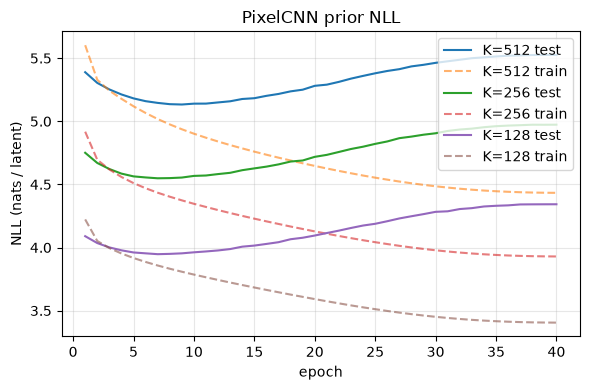

In [18]:
def train_pixelcnn(K):
    path = f"{CKPT}/pixelcnn_K{K}.pt"
    model = GatedPixelCNN(K, CFG["pcnn_dim"], CFG["pcnn_layers"]).to(device)
    if os.path.exists(path):
        ck = torch.load(path, map_location=device)
        model.load_state_dict(ck["model"]); print(f"PixelCNN K={K}: loaded checkpoint")
        return model, ck["hist"]
    tr, te = latents[K]
    opt = torch.optim.Adam(model.parameters(), lr=CFG["pcnn_lr"])
    steps = CFG["pcnn_epochs"] * math.ceil(len(tr) / CFG["bs"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    hist = {k: [] for k in ["epoch", "train_nll", "test_nll", "time"]}
    t0 = time.time()
    for ep in range(1, CFG["pcnn_epochs"] + 1):
        model.train()
        s, n = torch.zeros(1, device=device), 0
        for z in batches(tr, CFG["bs"]):
            loss = F.cross_entropy(model(z), z)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); sched.step()
            s += loss.detach() * len(z); n += len(z)
        model.eval()
        with torch.no_grad():
            test_nll = np.mean([F.cross_entropy(model(z), z).item() for z in batches(te, 1000, shuffle=False)])
        for k, v in zip(hist, [ep, (s / n).item(), test_nll, time.time() - t0]):
            hist[k].append(v)
        if ep == 1 or ep % 5 == 0 or ep == CFG["pcnn_epochs"]:
            print(f"PixelCNN K={K:>3} ep {ep:3d} | train NLL {(s / n).item():.3f} | test NLL {test_nll:.3f} nats/code "
                  f"({test_nll / math.log(2):.2f} bits) | {time.time() - t0:6.0f}s")
    torch.save({"model": model.state_dict(), "hist": hist}, path)
    return model, hist

pcnns, pcnn_hist = {}, {}
for K in CFG["Ks"]:
    seed_everything(SEED)
    pcnns[K], pcnn_hist[K] = train_pixelcnn(K)

plt.figure(figsize=(6, 4))
for K in CFG["Ks"]:
    plt.plot(pcnn_hist[K]["epoch"], pcnn_hist[K]["test_nll"], label=f"K={K} test")
    plt.plot(pcnn_hist[K]["epoch"], pcnn_hist[K]["train_nll"], "--", alpha=0.6, label=f"K={K} train")
plt.xlabel("epoch"); plt.ylabel("NLL (nats / latent)"); plt.title("PixelCNN prior NLL"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/pixelcnn_nll.png", dpi=150); plt.show()

### 4.1 Sampling new latent codes and generating images

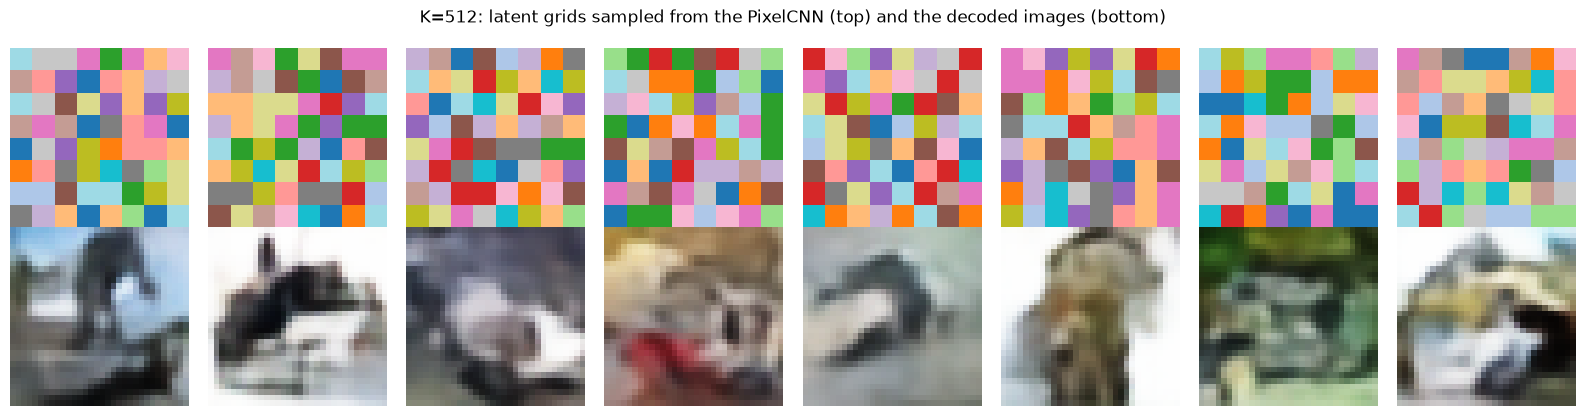

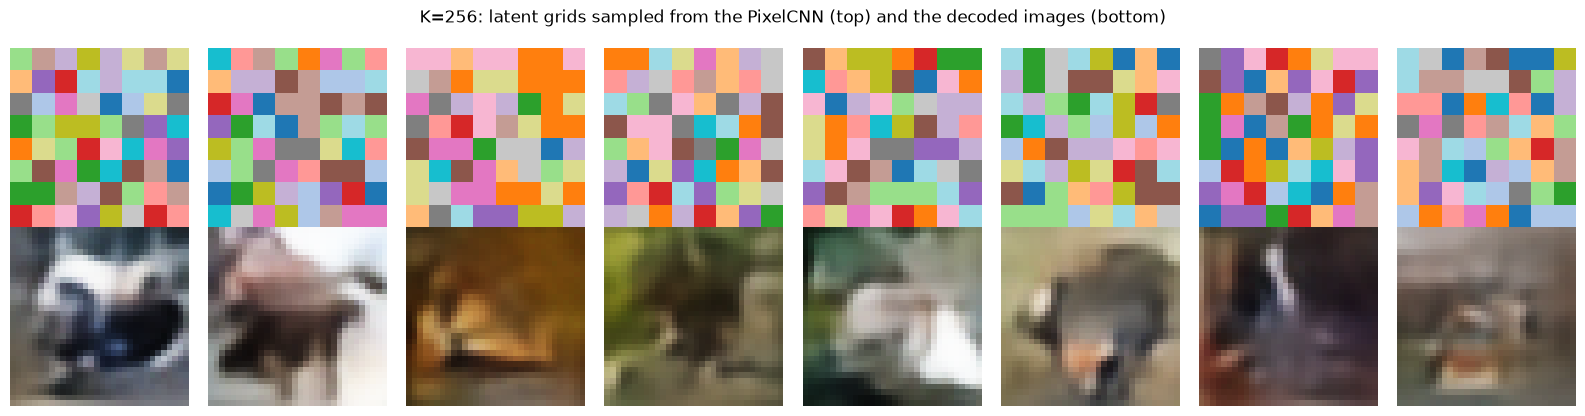

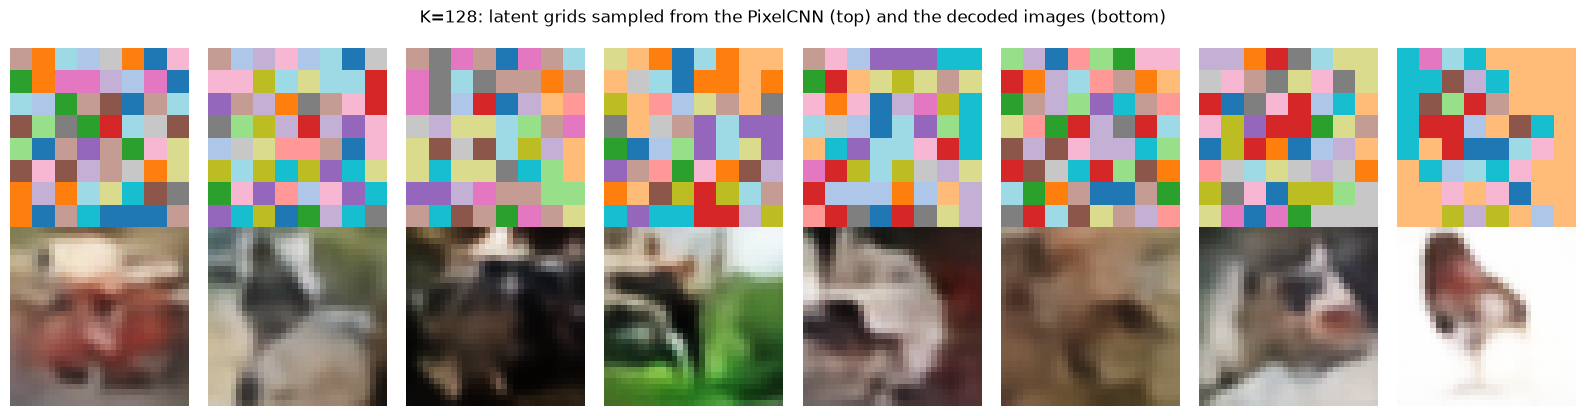

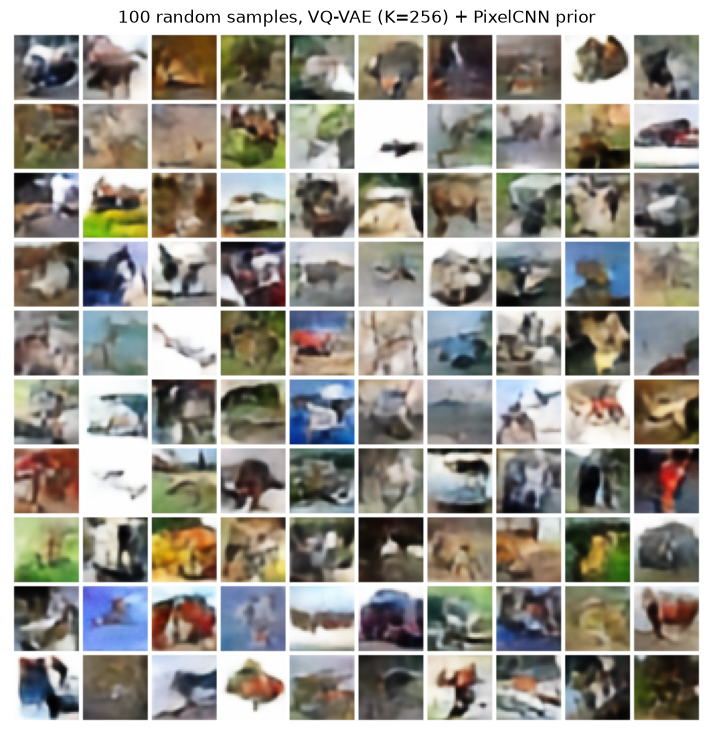

In [19]:
def vq_generate(K, n):
    return vqvaes[K].eval().decode_indices(pcnns[K].sample(n))

for K in CFG["Ks"]:
    seed_everything(SEED)
    z = pcnns[K].sample(8)
    fig, ax = plt.subplots(2, 8, figsize=(16, 4.2))
    imgs = vqvaes[K].decode_indices(z).cpu()
    for i in range(8):
        ax[0, i].imshow(z[i].cpu(), cmap="tab20", interpolation="nearest"); ax[0, i].axis("off")
        ax[1, i].imshow(imgs[i].permute(1, 2, 0).clamp(0, 1)); ax[1, i].axis("off")
    plt.suptitle(f"K={K}: latent grids sampled from the PixelCNN (top) and the decoded images (bottom)")
    plt.tight_layout(); plt.savefig(f"{FIG}/vqvae_K{K}_sampled_latents.png", dpi=120); plt.show()

seed_everything(SEED)
show_grid(vq_generate(K_show, 100), nrow=10, path=f"{FIG}/vqvae_K{K_show}_samples_100.png",
          title=f"100 random samples, VQ-VAE (K={K_show}) + PixelCNN prior", figsize=(9, 9))

### 4.2 FID, PSNR and codebook quality for different K

In [20]:
for K in CFG["Ks"]:
    psnr, perp, usage, dead, _ = vq_eval[K]
    m = vqvaes[K].eval()
    seed_everything(SEED)
    fid_sample = fid_scorer(sample_batches(lambda b: vq_generate(K, b), CFG["n_fid"], bs=1000))
    fid_recon = fid_scorer(m(xb)[0] for xb in batches(X_test, 500, shuffle=False))
    n_t = min(CFG["n_fid"], 1000)
    _, t_sample = timed(lambda: vq_generate(K, n_t))
    results["vqvae"][str(K)] = dict(
        psnr_hist=vq_hist[K]["test_psnr"], final_psnr=psnr, perplexity=perp, usage=usage, dead_codes=dead,
        fid_sample=fid_sample, fid_recon=fid_recon, pcnn_test_nll=pcnn_hist[K]["test_nll"][-1],
        train_time_vq_s=vq_hist[K]["time"][-1], train_time_pcnn_s=pcnn_hist[K]["time"][-1],
        train_time_s=vq_hist[K]["time"][-1] + pcnn_hist[K]["time"][-1],
        sample_time_10k_s=t_sample * 10000 / n_t,
        params=n_params(m) + n_params(pcnns[K]),
        bits_per_image=64 * math.log2(K))
    print(f"K={K}: PSNR {psnr:.2f} dB | perplexity {perp:.1f}/{K} | usage {usage*100:.1f}% | "
          f"sample FID {fid_sample:.2f} | recon FID {fid_recon:.2f}")

vq_df = pd.DataFrame({f"K={K}": {"Test PSNR (dB)": r["final_psnr"], "Perplexity": r["perplexity"],
                                 "Codebook usage (%)": 100 * r["usage"], "Dead codes": r["dead_codes"],
                                 "Bits / image": r["bits_per_image"], "PixelCNN test NLL": r["pcnn_test_nll"],
                                 "Sample FID ↓": r["fid_sample"], "Recon FID ↓": r["fid_recon"],
                                 "Train time (s)": r["train_time_s"]}
                      for K, r in ((int(k), v) for k, v in results["vqvae"].items())}).T
json.dump(results, open(f"{RES}/partA_results.json", "w"), indent=2)
vq_df.round(2)

K=512: PSNR 25.55 dB | perplexity 438.4/512 | usage 100.0% | sample FID 79.49 | recon FID 50.06


K=256: PSNR 24.97 dB | perplexity 222.6/256 | usage 100.0% | sample FID 81.61 | recon FID 57.59


K=128: PSNR 24.49 dB | perplexity 113.4/128 | usage 100.0% | sample FID 81.36 | recon FID 61.17


,Test PSNR (dB),Perplexity,Codebook usage (%),Dead codes,Bits / image,PixelCNN test NLL,Sample FID ↓,Recon FID ↓,Train time (s)
K=512,25.55,438.40,100.0,0.0,576.0,5.53,79.49,50.06,216.16
K=256,24.97,222.59,100.0,0.0,512.0,4.97,81.61,57.59,210.49
K=128,24.49,113.44,100.0,0.0,448.0,4.34,81.36,61.17,208.26


**Observations (VQ-VAE)**
* **Reconstruction.** The VQ-VAE reconstructs much better than the β-VAE: its PSNR is several dB higher and its recon FID is far lower. It keeps an 8×8 spatial grid of codes rather than squeezing everything into one global Gaussian vector, and it has no KL term pulling the codes towards an uninformative prior. A larger K gives a bigger information budget (64·log₂K bits per image), so PSNR improves slightly with K, although the gain gets smaller each time K doubles.
* **Codebook quality.** With EMA updates and dead-code restarts, almost all codes are used for every K, and the perplexity is a large fraction of K. The ratio perplexity/K falls slightly as K grows, because the larger codebooks contain more rarely used codes.
* **Generation.** Samples from the PixelCNN prior are sharper than VAE samples. They have proper edges and colours, because the decoder only ever sees "valid" code grids. However, they often lack global object structure. The PixelCNN is small and has to model a 64-position sequence, and its errors show up as texture-like or incoherent objects. A larger K makes the prior's job harder (higher NLL per code), so the best sample FID does not always come from the largest codebook.

## 5. Part A summary

In [21]:
summary = []
for b, r in results["vae"].items():
    summary.append({"Model": f"β-VAE (β={b})", "PSNR (dB)": r["final_psnr"], "Recon FID": r["fid_recon"],
                    "Sample FID": r["fid_sample"], "Train (min)": r["train_time_s"] / 60,
                    "Sampling 10k imgs (s)": r["sample_time_10k_s"]})
for K, r in results["vqvae"].items():
    summary.append({"Model": f"VQ-VAE (K={K}) + PixelCNN", "PSNR (dB)": r["final_psnr"], "Recon FID": r["fid_recon"],
                    "Sample FID": r["fid_sample"], "Train (min)": r["train_time_s"] / 60,
                    "Sampling 10k imgs (s)": r["sample_time_10k_s"]})
json.dump(results, open(f"{RES}/partA_results.json", "w"), indent=2)
print("saved", f"{RES}/partA_results.json")
pd.DataFrame(summary).set_index("Model").round(2)

saved outputs/results/partA_results.json


,PSNR (dB),Recon FID,Sample FID,Train (min),Sampling 10k imgs (s)
Model,,,,,
β-VAE (β=1),20.46,145.29,144.70,0.64,0.01
β-VAE (β=2),19.24,182.90,175.95,0.64,0.01
β-VAE (β=4),18.14,235.99,224.03,0.63,0.01
β-VAE (β=10),16.75,300.23,297.41,0.63,0.01
VQ-VAE (K=512) + PixelCNN,25.55,50.06,79.49,3.60,17.96
VQ-VAE (K=256) + PixelCNN,24.97,57.59,81.61,3.51,17.67
VQ-VAE (K=128) + PixelCNN,24.49,61.17,81.36,3.47,17.62
